# Prosjekt 2

By Erik Haddon, Vemund Solli Wilhelmsen, Herman Halvorsen Berggreen

When we first solved these problems we divided the work so that each person was given a method and had to solve 5A and 5B with this method. This worked, but when we tried to put our solutions together it turned out we had a lot of the same code written several times, which made the notebook unecessarily complicated. To make the code more understandable and less repeating, this notebook tries to use a common template so that we avoid this. The main idea is to have the model problems in dictionaries and reuse this code in the ODE-solvers. To compare plots it was also necessary to make functions that plot the methods solutions in common plots for each task. The code in this notebook was first written in a numpy format, but it turned out that this was too slow, so a JAX implementation was needed.

The structure is as follows:

- Imports

- Model problems

- Helper functions

- Solvers
    - Boris
    - RK4
    - Multistep
    - Overview of solvers

- 5A: Plotting trajectories and error over long time
    - Running all solvers
    - Plotting functions
    - Charged particle
        - 1: Trajectory
        - 2: Error
        - 3: Energy
    - Tokamak
        - 1: Trajectory and banana orbit
        - 2: Error
        - 3: Energy

- 5B: Order verification and work precision diagrams
    - Running all solvers timed
    - Plotting functions
    - Charged particle
        - 1: Order vertification
        - 2: Work precision diagram
    - Tokamak
        - 1: Order vertification
        - 2: Work precision diagram

- 5C: Exploratory
    - Implicit midpoint

- Conclusion

- Refrences

## Imports

In [1]:
# Necessary libraries
import scipy
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.lax as lax
import time
import numpy as np
from jax.experimental.ode import odeint
from functools import partial
from functools import lru_cache #need this one because we are using JAX (to measure time accurately)

jax.config.update("jax_enable_x64", True)

## Model Problems

In [2]:
def r(x: jax.Array) -> float:
    return jnp.sqrt(x[0]**2+ x[1]**2)

def r2(x: jax.Array) -> float:
    return x[0]**2+ x[1]**2

#### Charged Particle

In [3]:
def B_cp(x: jax.Array) -> jax.Array:
    return jnp.array([0, 0, r(x)])


def A_cp(x: jax.Array) -> jax.Array:
    return 1/3 * jnp.array([-x[1]*r(x), x[0]*r(x), 0])

def dA_cp(x: jnp.array) -> jnp.array:

    r = jnp.sqrt(x[0]**2 + x[1]**2)

    return jnp.array([[-1/3*x[0]*x[1]/ r, -1/3 * (r + x[1]**2/ r), 0*r],
                        [1/3 * (r + x[0]**2/r), 1/3 * x[0] * x[1]/r, 0*r],
                        [0*r,                   0*r,                      0*r]])

def U_cp(x: jax.Array) -> float:
    rr = jnp.clip(r(x), 1e-20, None) # To make sure the I dont get divide by zero errors
    return 1 / (100 * rr)

def gradU_cp(x: jax.Array) -> jax.Array:
    rr= jnp.clip(r(x), 1e-20, None) # TO make sure the I dont get divide by zero errors
    return -1/ 100 *jnp.array([x[0]/rr**3, x[1]/rr**3, 0])

# System of differential equations
@jax.jit
def system_cp(t: jax.Array, Y: jax.Array) -> jax.Array:
    x = Y[:3]
    v = Y[3:]
    dxdt = v
    dvdt = jnp.cross(v, B_cp(x)) - gradU_cp(x)
    return jnp.concatenate((dxdt, dvdt))

charged_particle = dict(
    name = "charged particle",
    x0 = jnp.array([0, 1, 0.1]),
    v0 = jnp.array([0.09, 0.05, 0.20]),
    B = B_cp,
    A = A_cp,
    dA = dA_cp,
    U = U_cp,
    gradU = gradU_cp,
    system = system_cp
)

#### Tokamak

In [4]:
def B_tok(x: jax.Array) -> jax.Array:
    """
    Returns the forces of the magnetic Field
    """

    rr2 = jnp.maximum(r2(x), 1e-20) # TO make sure the I dont get divide by zero errors
    rr = jnp.maximum(r(x), 1e-20) # TO make sure the I dont get divide by zero errors

    return jnp.array([-(2 * x[1] + x[0]*x[2]) / (2 *rr2),
                          (2*x[0] - x[1]*x[2]) / (2* rr2),
                                    (r(x) -1) / (2* rr)])


def A_tok(x: jax.Array) -> jax.Array:

    rr2 = jnp.maximum(r2(x), 1e-20) # TO make sure the I dont get divide by zero errors
    rr = jnp.maximum(r(x), 1e-20) # TO make sure the I dont get divide by zero errors

    return jnp.array([0, 
                     1/2  * ( x[0] - jnp.log(rr + x[0]) ), 
                     -1/2 * (x[2] * jnp.arctan2(x[1], x[0]) + jnp.log(rr2)) ])

def dA_tok(x: jnp.array) -> jnp.array:

    """
    Analytically computed Jacobian for A(x) in the Tokamak magnetic field

    x: position on form (x1, x2, x3)

    Returns a 3x3 Jacobian matrix
    """

    r = jnp.sqrt(x[0]**2+ x[1]**2)
    r2 = x[0]**2+ x[1]**2

    return jnp.array([ [0*r,     0*r     , 0*r],
                      [1/2 - (x[0]/r + 1) / (2 * (x[0] + r)), -x[1] / (2*(x[0] + r) * r), 0*r],
                       [-x[0]/r2 + x[1]*x[2]/(2 * r2), -x[1]/ r2 - x[0] * x[2] / (2 * r2), -jnp.atan2(x[1], x[0]) / 2]])


def U_tok(x: jax.Array) -> float:
    return 0.0

def gradU_tok(x: jax.Array) -> jax.Array:
    return jnp.array([0.0, 0.0, 0.0])


# # System of differential equations
@jax.jit
def system_tok(t: float, Y: jax.Array) -> jax.Array:
    x = Y[:3]
    v = Y[3:]
    dxdt = v
    dvdt = jnp.cross(v, B_tok(x)) - gradU_tok(x)
    return jnp.concatenate((dxdt, dvdt))

tokamak = dict(
    name = "tokamak",
    x0 = jnp.array([1.2, 0.0, 0.0]),
    v0 = jnp.array([0.0, 4.816e-4, -2.059e-3]),
    B = B_tok,
    A = A_tok,
    dA = dA_tok,
    U = U_tok,
    gradU = gradU_tok,
    system = system_tok
)

## Helper functions

In [5]:
#need this function because the timed jax ode solver was wrong before
#to make odeint remember f so it doesnt compile it repeatedly
@lru_cache(maxsize=None)
def odeint_rhs(system, sign=1.0):
    """
    The right-hand side in the form expected by odeint is: f(Y, t) = sign * system(t, Y).

    lru_cache ensures that the same system returns the same function object,
    so odeint does not recompile on every call.
    """

    def f(Y, t):
        return sign * system(t, Y)
    return f

def energy(problem, x, v):
    U = jax.vmap(problem["U"], in_axes=1)
    return 0.5 * jnp.sum(v**2, axis=0) + U(x)


def reference_solution(problem, t_eval):
    Y0 = jnp.concatenate([problem["x0"], problem["v0"]])

    Y = odeint(odeint_rhs(problem["system"]), Y0, jnp.asarray(t_eval), rtol=1e-12, atol=1e-12).T

    return t_eval, Y[:3], Y[3:]

def timed(solve, problem, h, T):

    #lets jit warm up one round before measuring the actual compute time
    jax.block_until_ready(solve(problem, h, T))
    
    start = time.perf_counter()
    out = jax.block_until_ready(solve(problem, h, T))

    return out, time.perf_counter() - start

## Solvers

### Boris

In [6]:
@partial(jax.jit, static_argnames=("B", "gradU", "T", "h"))
def Boris_method(v_init: jnp.array, x0: jnp.array, B, gradU, T: int, h: float) -> tuple[jnp.array, jnp.array]:

    """
    Boris_method, calculates the position and velocity of the particle at time t.

    x0: Iinitial position, array of size 3.
    v0: Iinitial velocity, array of size 3.
    T:  Total time.
    h:  Steplength in time.

    return: arrays of positions and velocities.
    """

    N = int(round(T/h))

    x = x0
    v = v_init

    def Boris_step(x: jnp.array, v: jnp.array) -> tuple[jnp.array, jnp.array]:
        """
        Calculates one step of the Boris method


        x: Current position, array of size 3.
        v: Current velocity, array of size 3.
        h:  Steplength in time.
        
        return: x_next, v_nect
        """

        v_minus = v -  h/2 * gradU(x)    #v_minus

        t = h/2 * B(x)
        s = 2 * t / (1 + t @ t)
        v_prime = v_minus + jnp.cross(v_minus, t)
        v_plus = v_minus + jnp.cross(v_prime, s) 

        v_next = v_plus - h/2 * gradU(x)
        x_next = x + h * v_next

        return x_next, v_next

    def body(carry, _):
        x, v  = carry
        x, v = Boris_step(x, v)

        return (x, v), (x,v)

    (_, _), trajectory = lax.scan(body, (x, v), xs = None, length = N+1)

    positions, velocities = trajectory

    positions = jnp.concatenate([x0[None, :], positions], axis=0)

    velocities = jnp.concatenate([v_init[None, :], velocities], axis=0)
    v_averages = 1/2 * (velocities[:-1] + velocities[1:])
    return positions[:-1].T, v_averages.T

#wrapper function, "main"
def boris(problem, h, T):
    
    # v(-h/2): odeint needs increasing t, so we integrate -f forwards instead of f backwards
    Y0 = jnp.concatenate([problem["x0"], problem["v0"]])
    Y_half = odeint(odeint_rhs(problem["system"], -1.0), Y0, jnp.array([0.0, h/2]),
                    rtol=1e-12, atol=1e-12)
    v_init = Y_half[-1, 3:]

    x, v = Boris_method(v_init, problem["x0"], problem["B"], problem["gradU"], T, h)
    N = int(round(T/h))
    t = h * jnp.arange(N + 1)
    return t, x, v

### RK4

In [7]:
def RK4_step(t:jax.Array, Yn:jax.Array, system:jax.Array, h:float) ->jax.Array:
    """
    t: time (is ignored here)
    Yn: [x1,x2,x3,v1,v2,v3]
    system: gives dY/dt (RHS of differential equation)
    h: steplength
    returns: Yn_new

    """
    k1 = h * system(t, Yn)
    k2 = h * system(t, Yn + 0.5*k1)
    k3 = h * system(t, Yn + 0.5*k2)
    k4 = h * system(t, Yn + k3)

    Yn_new = Yn + 1/6*(k1 + 2*k2 + 2*k3 + k4)

    return Yn_new

@partial(jax.jit, static_argnames=("system", "N"))
def rk4_subwrap(N: int,  Y0:jax.Array, system, h:float) -> jax.Array:
    """
    N: number of steps
    Y0: initial Y vector
    system: RHS differential eqt
    h: step length
    """
    def body(Yn, _):
        Yn_new = RK4_step(0.0, Yn, system, h)
        return Yn_new, Yn_new

    Y_final, trajectory = lax.scan(body, Y0, xs=None, length=N)
    
    Y = jnp.concatenate((Y0[None, :], trajectory), axis=0).T

    return Y

#wrapper function, "main"
def rk4(problem, h, T):
    N = int(round(T / h))
    Y0 = jnp.concatenate([problem["x0"], problem["v0"]])
    Y = rk4_subwrap(N, Y0, problem["system"], h)
    t = h * jnp.arange(N+1)
    return t, Y[:3], Y[3:]

### Multistep

In [8]:
# Constants for fourth order symmetric multistep
a1 = -0.7
a2 = 0.1
a3 = 0.9

beta0 = (1/3) * (20*a1*a2*a3 - 4*(a1*a2 + a1*a3 + a2*a3) - 28*(a1 + a2 + a3) - 52)
beta1 = (1/3) * (2*a1*a2*a3 + 14*(a1*a2 + a1*a3 + a2*a3) + 26*(a1 + a2 + a3) + 38)

alpha_list = jnp.array([
    1,           # α₋₄
    -7/5,        # α₋₃
    9/25,        # α₋₂
    22/125,      # α₋₁
    -34/125,     # α₀
    22/125,      # α₁
    9/25,        # α₂
    -7/5,        # α₃
    1            # α₄
])

@jax.jit
def delta_yj(y: jnp.array) -> float:
    """
    Five point central difference centered in y[2]

    y: array on form (y_j-2, y_j-1, y_j, y_j+1, y_j+2). Each y has 3 components

    Returns the central difference
    """

    return 1/12 * (y[:,0] - 8 * y[:,1] + 8* y[:,3] - y[:,4]) 

@jax.jit
def F_j_jax(A_x :jnp.array, x :jnp.array,  h: float, U_grad_xj: jnp.array, A_jacobian: jnp.array) -> jnp.array:
    """
    Fourth order symmetric multistep method help function

    x: array with shape (x_j-2, x_j-1, x_j, x_j+1, x_j+2). Each x has 3 compontents
    h: steplength
    U_grad: potential gradient function

    Returns a 3 component array
    """

    x_j = x[:, 2]
    delta_Aj = delta_yj(A_x)/ h
    vj = delta_yj(x)/ h

    return  A_jacobian.T @ vj - delta_Aj - U_grad_xj


def fourth_order_sym_multistep_step_fast(x: jnp.array, alpha: jnp.array, h: float, beta0: float, beta1: float, F: tuple) -> jnp.array:

    """
    Takes a step in the fourth order symmetrical multistep method

    x: array on form (x_n-4, x_n-3, ... , x_n+4)
    alpha: array on form (alpha_n-4, alpha_n-3, ... , alpha_n+4)
    h: steplength
    beta0, beta1: method parameters, 
    F: tuple on form (F_n-1, F_n, F_n+1)

    Returns an array x with updated x_n+4
    """

    prev_steps = jnp.sum(x * alpha[:-1], axis = 1)
    x_n4 = 1/ alpha[-1] *( h**2 * (beta1 * F[0] + beta0 * F[1] + beta1 * F[2]) - prev_steps)
    #x[-1] = x_n4

    return x_n4


@partial(jax.jit, static_argnames=("t_size", "U_grad", "A", "jacobian"))
def fourth_order_sym_multistep_lax(x: jnp.array, v: jnp.array, t_size: int, alpha: jnp.array, h: float, beta0: float, beta1: float, U_grad: callable, A: callable, jacobian: callable) -> jnp.array:

    """
    Fourth order symmetrical multistep method

    x: array with same shape as the final position array, except with the inital 8 values computed
    v: same as x but for velocity
    t_size: number of time points
    alpha: array on form (alpha_n-4, alpha_n-3, ... , alpha_n+4)
    h: steplength
    beta0, beta1: method parameters, 
    U_grad: potential gradient function
    A: magnetic field vector potential function
    Jacobian: Analytically computed jacobian of A 

    Returns a dict with x and v as keys
    """
    A = jax.vmap(A, in_axes=1, out_axes=1)

    def scan_step(carry: tuple, _) -> jnp.array:

        """
        This function does the iterations in the multistep method. We initially implemented the 
        multistep method with numpy and a for loop here, but this took to much time. This function combined with lax.scan
        computes the values at every iteration simultanously

        carry: tuple of values which are updated for each iteration.
               Has the form (x_window, F_prev, F_n, F_next) 
               x_window: array of x_n-4 to x_n+3 (x_n+4 is the value we compute in each iteration)
               F_prev, F_n, F_next: F centered at x_n-1, x_n, x_n+1 respectively


        Returns new carry which are the updated iterative values, and x_last which is 
        an array of every x computed up to this point
        """

        x_window, v_current, F_prev, F_n, F_next = carry 

        # Compute new position
        x_last = fourth_order_sym_multistep_step_fast(x_window, alpha, h, beta0, beta1, (F_prev, F_n, F_next))

        # New window of x_n-4 to x_n+3 (x_n+4 is the value we compute in each iteration)
        new_x_window = jnp.concatenate([x_window[:, 1:], x_last[:, None]],axis=1)

        # Compute velocity as five point difference
        v_current =  delta_yj(new_x_window[:, -5:]) / h 

        # Update the F functions in each itearation
        F_prev = F_n                                        # Need five x-values centered around -5
        F_n = F_next                                        # Need five x-values centered around -4
        A_jacobi_next = jacobian(new_x_window[:, -3])
        U_grad_next = U_grad(new_x_window[:, -3])
        A_next = A(new_x_window[:, -5:])
        F_next = F_j_jax(A_next, new_x_window[:, -5:], h, U_grad_next, A_jacobi_next)     # Need five x-values centered around -3

        # Save current values for next iteration
        new_carry = (new_x_window, v_current, F_prev, F_n, F_next)
        
        return new_carry, (x_last, v_current)

    # Find initial values of the Fs
    A_jacobi_next = jacobian(x[:, 3])
    U_grad_next = U_grad(x[:, 3])
    A_next = A(x[:,  (1): (6)])
    F_prev = F_j_jax(A_next, x[:, (1): (6)],  h, U_grad_next, A_jacobi_next)     # Need five x-values centered around 3

    A_jacobi_next = jacobian(x[:, 4])
    U_grad_next = U_grad(x[:, 4])
    A_next = A(x[:,  (2): (7)])
    F_n = F_j_jax(A_next, x[:, (2): (7)], h, U_grad_next, A_jacobi_next)         # Need five x-values centered around 4

    A_jacobi_next = jacobian(x[:, 5])
    U_grad_next = U_grad(x[:, 5])
    A_next = A(x[:, (3): (8)])
    F_next = F_j_jax(A_next, x[:, (3): (8)], h, U_grad_next, A_jacobi_next)      # Need five x-values centered around 5

    
    # Inital values for lax.scan
    init_x_window = x[:, :8]
    initial_carry = (init_x_window, v[:, 7], F_prev, F_n, F_next)

    # lax.scan computes every value in the multistep iteration simultanously
    final_carry, final_xv = lax.scan(scan_step, initial_carry,  xs= None, length = t_size - 9)

    # Final x holds every x-value computed in the lax scan
    # x holds the 8 initial values
    x_full = jnp.concatenate([x[:, :8], final_xv[0].T],axis=1)
    v_full = jnp.concatenate([v[:, :8], final_xv[1].T],axis=1)

    return {"x": x_full, "v": v_full}

def create_grids(problem, h: float, N: int):

      
    # Create grids
    t = h * jnp.arange(N + 4)
    x = jnp.zeros(( 3, t.size))
    v = jnp.zeros(( 3, t.size))
    
    # Find first eight x values with intode RK45
    _, x_init, v_init = reference_solution(problem, t[:8])
    x = x.at[:, :8].set(x_init)
    v = v.at[:, :8].set(v_init)

    return x, v, t

#wrapper function
def multistep(problem, h, T):
    N = int(round(T /h))
    x, v, t = create_grids(problem, h, N)

    result = fourth_order_sym_multistep_lax(x, v, int(t.size), alpha_list, h, beta0, beta1,
                                         problem["gradU"], problem["A"], problem["dA"])
    x_ext = result["x"]

    v_mid = (x_ext[:, :-4] - 8*x_ext[:, 1:-3] + 8*x_ext[:, 3:-1] - x_ext[:, 4:]) / (12*h)
    v = jnp.concatenate([v[:, :2], v_mid], axis=1)

    return t[:N+1], x_ext[:, :N+1], v

### Overview of solvers

In [9]:
solvers = {
    "Boris":     dict(solve=boris,     order=2, color="C0"),
    "RK4":       dict(solve=rk4,       order=4, color="C1"),
    "Multistep": dict(solve=multistep, order=4, color="C2"),
}
problems = [charged_particle, tokamak]

## 5A: Plotting trajectories and error over long time

info 

### Running all solvers

In [10]:
#run all solvers one time each for each problem
H = 0.1
T = 1e5      

results = {}        
refs = {}           

for problem in problems:
    problem_name = problem["name"]
    results[problem_name] = {}
    for solver_name, s in solvers.items():
        results[problem_name][solver_name] = s["solve"](problem, H, T)
    t = results[problem_name]["RK4"][0]
    refs[problem_name] = reference_solution(problem, t)

### Plotting functions

In [11]:
def plot_trajectories(problem, results):
    """(x1, x2) trajectory, one for each method and problem"""

    result = results[problem["name"]]
    fig, axes = plt.subplots(1, len(result), figsize=(4 * len(result), 4), sharex=True, sharey=True)

    for ax, (name, (t, x, v)) in zip(axes, result.items()):
        ax.plot(x[0, :], x[1, :], color=solvers[name]["color"], lw=0.5)
        ax.set_title(name)
        ax.set_xlabel(r"$x_1$")
        ax.set_aspect("equal")

    axes[0].set_ylabel(r"$x_2$")
    fig.suptitle(f"Trajectory in the $(x_1, x_2)$-plane, {problem['name']}")
    plt.tight_layout()
    plt.show()


def plot_R_x3(problem, results):
    """R = sqrt(x1^2 + x2^2) against x3 for each method for the tokamak problem"""

    result = results[problem["name"]]
    fig, axes = plt.subplots(1, len(result), figsize=(4 * len(result), 4), sharex=True, sharey=True)

    for ax, (name, (t, x, v)) in zip(axes, result.items()):
        R = jnp.sqrt(x[0]**2 + x[1]**2)
        ax.plot(R, x[2, :], color=solvers[name]["color"], lw=0.5)
        ax.set_title(name)
        ax.set_xlabel(r"$R = \sqrt{x_1^2 + x_2^2}$")

    axes[0].set_ylabel(r"$x_3$")
    fig.suptitle(f"Banana orbit, {problem['name']}")
    plt.tight_layout()
    plt.show()


def plot_error(problem, results, refs):
    """2_norm(x_n - x_ref(t_n)) over time for all methods in same figure"""

    result = results[problem["name"]]
    ref = refs[problem["name"]]
    _, x_ref, _ = ref
    plt.figure(figsize=(7, 4))

    for name, (t, x, v) in result.items():
        err = jnp.linalg.norm(x - x_ref, axis=0)
        plt.semilogy(t[1:], err[1:], color=solvers[name]["color"], label=name)

    plt.xlabel(r"$t_n$")
    plt.ylabel(r"$\|x_{(n)} - x_{\mathrm{ref}}(t_n)\|_2$")
    plt.title(f"Global error, {problem['name']}")
    plt.legend()
    plt.show()


def plot_energy(problem, results):
    """abs(E(x_n, v_n) - E(x_0, v_0)) over time for all methods"""
    
    result = results[problem["name"]]
    E0 = energy(problem, problem["x0"][:, None], problem["v0"][:, None])[0]   
    plt.figure(figsize=(7, 4))

    for name, (t, x, v) in result.items():
        e = jnp.abs(energy(problem, x, v) - E0)
        plt.semilogy(t[1:], e[1:], color=solvers[name]["color"], label=name)

    plt.xlabel(r"$t_n$")
    plt.ylabel(r"$|E(x_{(n)}, v_{(n)}) - E(x_{(0)}, v_{(0)})|$")
    plt.title(f"Energy error, {problem['name']}")
    plt.legend(loc = "lower left")
    plt.show()

### Charged particle

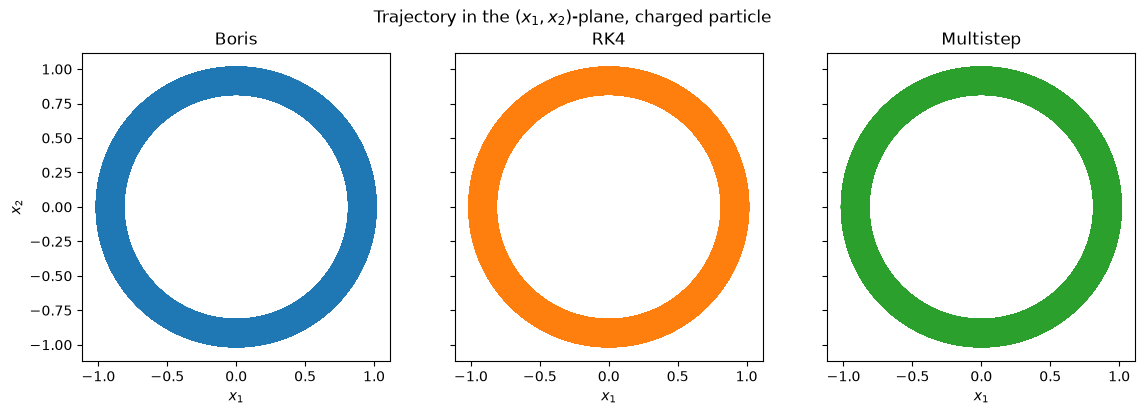

In [12]:
plot_trajectories(charged_particle, results)

As we see in the figures above all ODE solvers seem to plot out the trajectory approximately the same, but it is hard to see how exact they are as much of the plot is overlap, which is what causes the thickness of the circle. This happens because the particle is actually moving in a combination two circle movements, one small one and one large one. The small circle movement is caused by the force v x B being perpendicular to the velocity. The thickness of the large circle is approximately the diameter of the small circle. This can be seen more clearly over a smaller time interval (T = 10^3). The reason for the big circle is caused by the the potential field U being stronger near the center (0, 0) and weaker away from it. This causes the particle to be accelerated on its way out, and deaccelerated on its way in, which causes the outer side of the small circle to be larger than the inner side. This causes a net drift with the clock, which creates the large cicle. At the same time we still have v x B, and B is weaker near the center (0, 0). This effect is actually opposite of the previous, but the previous effect turns out to be stronger so the particle moves with the clock. This is what causes the Particle to have an annulus orbit in the 2D plane.

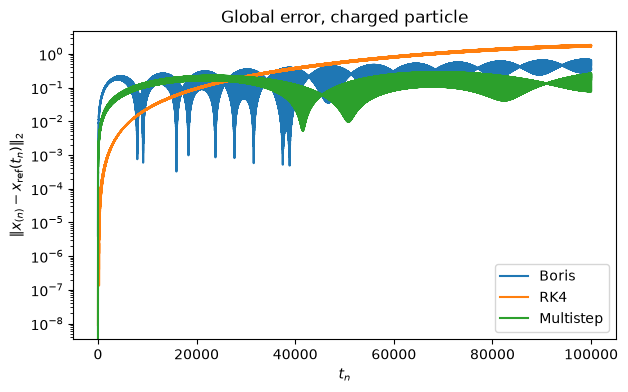

In [13]:
plot_error(charged_particle, results, refs)

As we see in the plot above in the beginning the boris method has the highest error followed by multistep and with RK4 having the lowest error. However after time of around 3*10^4 the error of RK4 surpasss both Boris and the Multistep method. As time moves ov RK4 error continues to increase, while the error for the Boris method increases slighly more than for Multistep, but both seem to flat out, but still above around 0.1 at the end. This is a sign that they might be out of sync with the small circle movement. We also see that RK4 seems to approach the maximum error of around 2, as this is when the RK4 particle is completely out of phase with the reference solution particle (RK4 is a good enough solution to be able to always keep the particle in the annulus at least, as in the previous plot). We also notice that both the Boris and Multistep method have some thickness in their plots. This is caused by the rapidly changing errors between timesteps close to eachother.

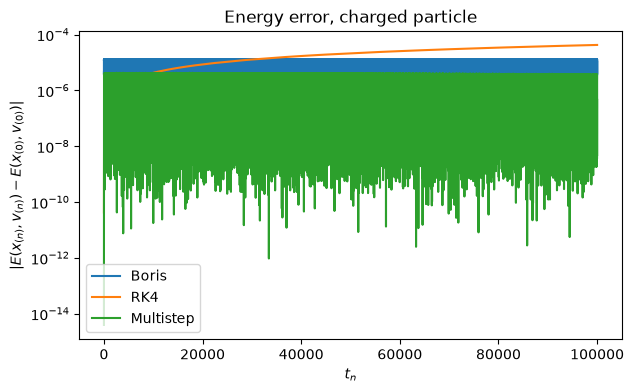

In [14]:
plot_energy(charged_particle, results)

In the plot above we see how the different ODE solvers do when it comes to conserving energy. In the beginning RK4 actually beats Boris and Multistep, but not over longer time intervals. As we can see this is where RK4 has a weakness, its error seems to be increasing rather steadily. At the same time both Boris and Multistep energy error seem to stay rather constant. They oscillate a lot up and down, which causes the plots to look filled in, but they are bounded and never cross their respective line which is about 10^-5 for Boris and 5*10^-6 for Multistep for the whole time interval. This plot seems to confirm theorem 3.2 (referred to theorem 3.1 in project) which states that s-stable symmetric multistep methods of order p, which multistep is, are good at conserving energy up to times of around h^(-p-2), which gives 10^6 for p = 4 and h = 0.1

### Tokamak

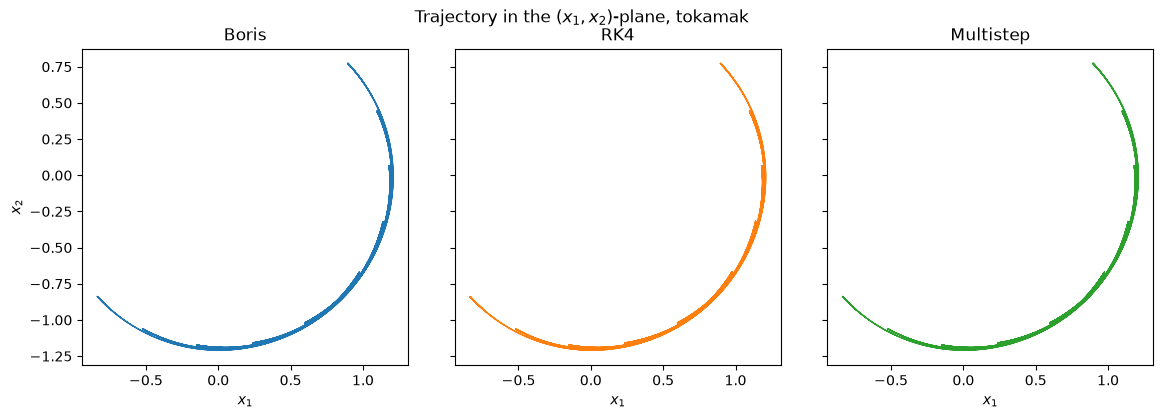

In [15]:
plot_trajectories(tokamak, results)

As we see in the plot above all methods seem to give approximately the same trajectory. The graph looks like a half circle which spans from around -135 degrees counterclockwise to around 45 degrees. The reason the particle does not go around the whole torus is that it is reflected back when it moves towards smaller R, where the magnetic field B is stronger (a magnetic mirror). After every bounce/reflection the particle drifts a little further clockwise around the torus, and given enough time it creates a full circle. This drift is caused by B being weaker on the outer side of the small gyration circle, which makes the particle drift vertically, moving it slowly onto neighbouring field lines.

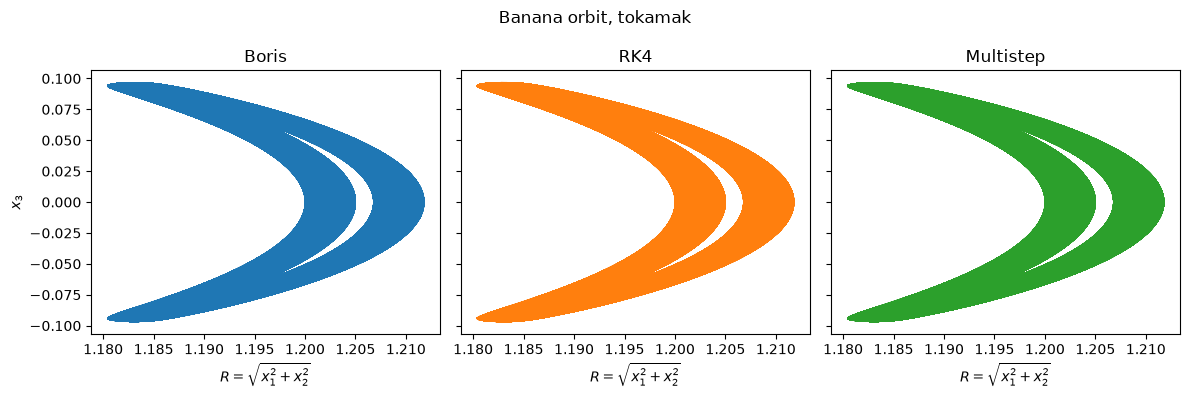

In [16]:
plot_R_x3(tokamak, results)

As we see in the plot above all methods give the same form and are almost identical. The plot shows a cross-section of the torus, and we see the particle move from around 1.18 to 1.21 in R, and from x3 = -0.1 to around x3 = 0.1, where it bounces back (the tips of the banana are the turning points). The two legs are caused by the vertical drift discussed in the previous plot: on the way down the particle has drifted slightly outwards, and on the way up slightly inwards, so it takes two different paths. It's filled in because of the small gyration circles around the field line.

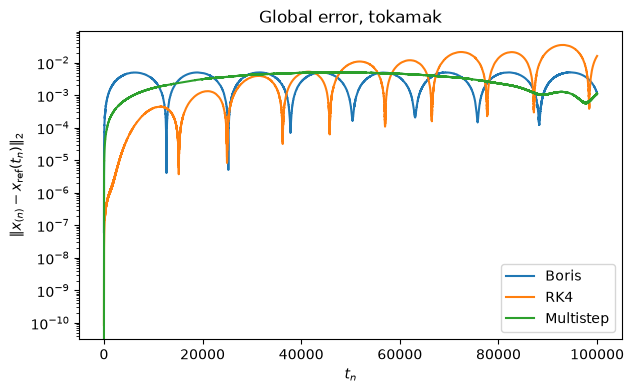

In [17]:
plot_error(tokamak, results, refs)

Here we see that RK4 and Boris seem to have an oscillating pattern of the global error, while Multistep is smoother. In the beginning RK4 has the lowest error, until around t = 2·10^4. However, the errors of both Boris and Multistep stay bounded at around 5·10^-3, while the peaks of RK4 increase steadily and end up about 10 times higher. The oscillations come from a phase error in the bouncing motion, where the numerical particle is slightly ahead of or behind the reference, and the deep dips are when they cross each other. Compared to the charged particle, the errors are small relative to the size of the banana orbit, so none of the methods get completely out of phase.

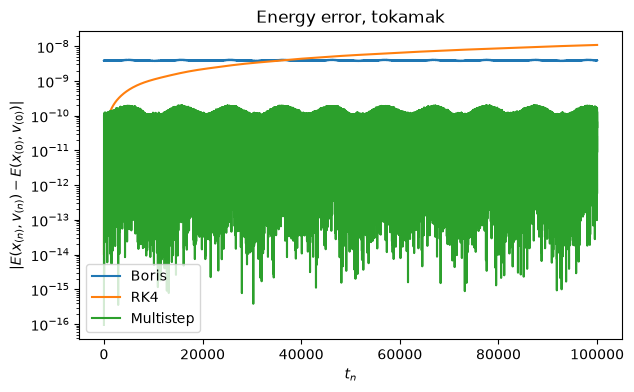

In [18]:
plot_energy(tokamak, results)

Here we see the energy error of the three methods. As we see, Boris is able to stay completely stable at around 4·10^-9, Multistep stays bounded below 10^-10 and is the most accurate, but is a bit wavy. RK4 starts with the lowest error, but seems to be ever increasing and passes Boris at around t = 3.5·10^4, which we have observed for the charged particle as well. Since U = 0 here, the energy is only kinetic, E = ½|v|^2 ≈ 2.2·10^-6, so the relative errors are about 0.2 % for Boris and 0.5 % for RK4 at the end. Boris actually conserves |v| exactly in each step, since the magnetic part is a pure rotation of the velocity, so the constant error comes from averaging the half-step velocities to get v_n.

## 5B:  Order verification and work precision diagrams

### Running all solvers timed

In [19]:
H_LIST = [0.1, 0.05, 0.025]
T_SHORT = 1000

errors = {}     # errors[problem_name][solver_name] = [e_0, e_1, e_2], en per h
times = {}  

for problem in problems:
    problem_name = problem["name"]

    # Referanseløsningen trengs bare i sluttpunktet T
    _, x_ref, _ = reference_solution(problem, jnp.array([0.0, T_SHORT]))
    x_ref_T = x_ref[:, -1]

    errors[problem_name] = {}
    times[problem_name] = {}
    for solver_name, s in solvers.items():
        errors[problem_name][solver_name] = []
        times[problem_name][solver_name] = []
        for h in H_LIST:
            (t, x, v), tau = timed(s["solve"], problem, h, T_SHORT)
            errors[problem_name][solver_name].append(float(jnp.linalg.norm(x[:, -1] - x_ref_T)))
            times[problem_name][solver_name].append(tau)


### plotting functions

In [20]:
def plot_order(problem, errors):

    problem_errors = errors[problem["name"]]
    h = np.array(H_LIST)
    plt.figure(figsize=(6, 5))

    for solver_name, e in problem_errors.items():
        plt.loglog(h, e, "o-", color=solvers[solver_name]["color"], label=solver_name)

    # Referanselinjer for p = 2 og p = 4
    plt.loglog(h, h**2, "k--", label=r"$h^2$")
    plt.loglog(h, h**4, "k:", label=r"$h^4$")

    plt.xlabel(r"$h_i$")
    plt.ylabel(r"$\|x_{(N_i)} - x_{\mathrm{ref}}(T)\|_2$")
    plt.title(f"Order verification, {problem_name}, T = {T_SHORT:g}")
    plt.legend()
    plt.show()

def plot_work_precision(problem, errors, times):
    problem_errors = errors[problem["name"]]
    problem_times = times[problem["name"]]
    plt.figure(figsize=(6, 5))

    for solver_name in solvers:
        e = problem_errors[solver_name]
        tau = problem_times[solver_name]
        plt.loglog(e, tau, "o-", color=solvers[solver_name]["color"], label=solver_name)

    plt.xlabel(r"Error $e_i$")
    plt.ylabel(r"Computation time $\tau_i$ [s]")
    plt.title(f"Work-precision diagram, {problem['name']}, T = {T_SHORT:g}")
    plt.legend()
    plt.show()


### Charged particle

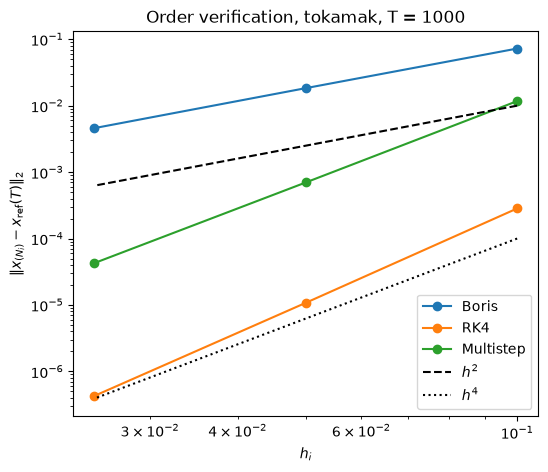

In [21]:
plot_order(charged_particle, errors)

kommentar

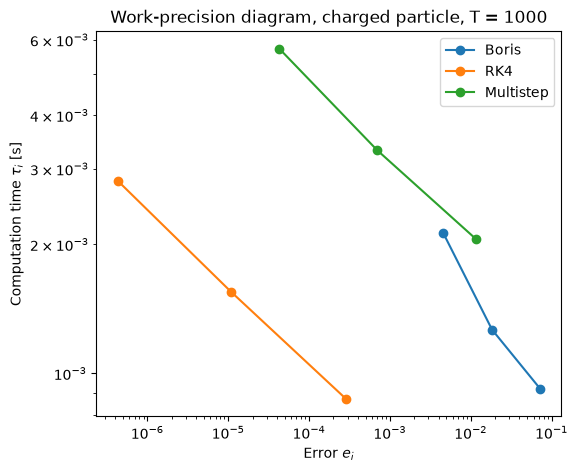

In [22]:
plot_work_precision(charged_particle, errors, times)

kommentar

### Tokamak

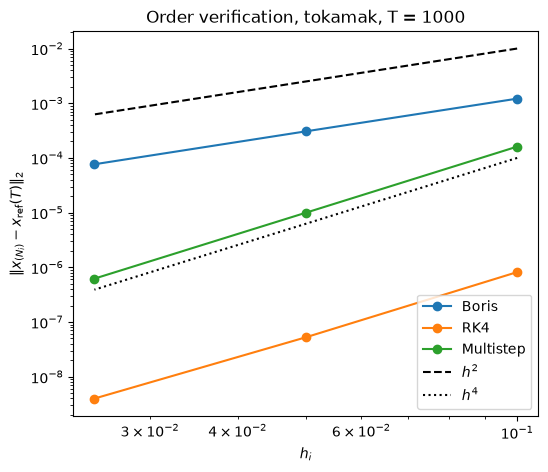

In [23]:
plot_order(tokamak, errors)

kommentar

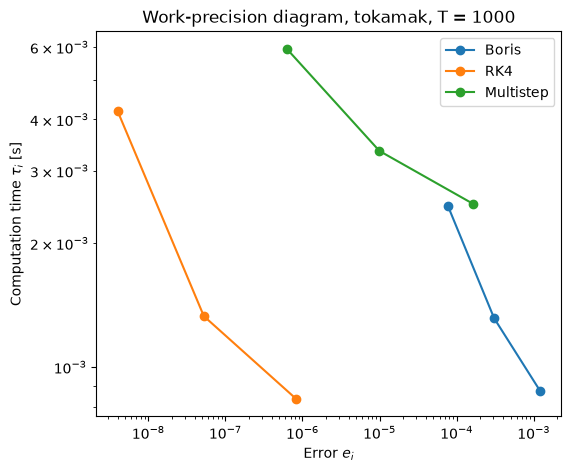

In [24]:
plot_work_precision(tokamak, errors, times)

kommentar

## 5C: Exploratory 

### Implicit midpoint

COMMENTS

## References

[0] TMA4215 Numerical Mathematics, *Project: Numerical Integrators for Charged Particles*, NTNU, 2026.

[1] J. P. Boris et al. Relativistic plasma simulation-optimization of a hybrid code. In *Proc. Fourth Conf. Num. Sim. Plasmas*, pages 3–67, 1970.

[2] E. Hairer and C. Lubich. Symmetric multistep methods for charged-particle dynamics. *The SMAI Journal of Computational Mathematics*, 3:205–218, Oct. 2017. ISSN 2426-8399. doi: [10.5802/smai-jcm.25](https://smai-jcm.centre-mersenne.org/articles/10.5802/smai-jcm.25/).

[3] Y. He, Y. Sun, J. Liu, and H. Qin. Volume-preserving algorithms for charged particle dynamics. *Journal of Computational Physics*, 281:135–147, Jan. 2015. ISSN 0021-9991. doi: [10.1016/j.jcp.2014.10.032](https://linkinghub.elsevier.com/retrieve/pii/S0021999114007141).
